In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

In [2]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [3]:
# Check whether the dataset exists locally
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / "anon2026_50k.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape}")

Dataset loaded successfully: (50000, 96)


In [4]:
df.head()

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 96 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PROP_TYPE          50000 non-null  str    
 1   PROP_AGE_BAND      50000 non-null  int64  
 2   FLOOR_AREA_BAND    50000 non-null  int64  
 3   CONSERVATORY_FLAG  9539 non-null   float64
 4   COUNCIL_TAX_BAND   50000 non-null  str    
 5   IMD_BAND_ENG       47578 non-null  float64
 6   IMD_BAND_WALES     2422 non-null   float64
 7   REGION             50000 non-null  str    
 8   EPC                50000 non-null  str    
 9   LI_FLAG            50000 non-null  int64  
 10  LI_DATE            7180 non-null   float64
 11  CWI_FLAG           50000 non-null  int64  
 12  CWI_DATE           7164 non-null   float64
 13  PV_FLAG            50000 non-null  int64  
 14  PV_DATE            800 non-null    float64
 15  MAIN_HEAT_FUEL     50000 non-null  int64  
 16  Gcons2024          39502 non-null

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PROP_TYPE,50000,6,Semi detached,12592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROP_AGE_BAND,"50,000.00",NaN,NaN,NaN,2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"50,000.00",NaN,NaN,NaN,2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,539.00",NaN,NaN,NaN,0.12,0.33,0.00,0.00,0.00,0.00,1.00
COUNCIL_TAX_BAND,50000,9,A,11539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
ElecValFlag2009,49230,5,V,40793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2008,49230,5,V,40179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2007,49230,5,V,39781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2006,49230,5,V,39796,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df_clean = df.copy()

In [8]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 2


In [9]:
duplicates = df_clean[df_clean.duplicated(keep=False)]

display(duplicates)

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
3238,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
9334,Flat,4,1,0.00,A,1.00,NaN,E12000002,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
10461,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
16923,Flat,4,1,0.00,C,2.00,NaN,E12000007,A/B,0,NaN,0,NaN,0,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,L,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O


In [10]:
df_clean = df_clean.drop_duplicates().copy()

print("Remaining rows:", len(df_clean))

Remaining rows: 49998


In [11]:
display(df_clean[df_clean.duplicated(keep=False)])

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005


In [12]:
print("Total rows:", len(df_clean))
print("Total columns:", len(df_clean.columns))

Total rows: 49998
Total columns: 96


In [13]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PROP_TYPE,50000,6,Semi detached,12592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROP_AGE_BAND,"50,000.00",NaN,NaN,NaN,2.34,1.04,1.00,2.00,2.00,3.00,4.00
FLOOR_AREA_BAND,"50,000.00",NaN,NaN,NaN,2.29,0.91,1.00,2.00,2.00,3.00,5.00
CONSERVATORY_FLAG,"9,539.00",NaN,NaN,NaN,0.12,0.33,0.00,0.00,0.00,0.00,1.00
COUNCIL_TAX_BAND,50000,9,A,11539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
ElecValFlag2009,49230,5,V,40793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2008,49230,5,V,40179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2007,49230,5,V,39781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ElecValFlag2006,49230,5,V,39796,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
display(df_clean)

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,Detached,1,5,NaN,F,5.00,NaN,E12000002,No EPC,0,NaN,0,NaN,0,NaN,1,"33,200.00","33,800.00","39,100.00","44,100.00","47,900.00","43,400.00","38,600.00","38,600.00","40,000.00",...,"5,300.00","5,300.00","4,900.00","5,900.00","5,700.00",V,V,V,V,V,V,V,V,V,V,V,V,O,V,V,V,V,V,V,V
49996,Semi detached,1,3,NaN,D,5.00,NaN,E12000006,D,0,NaN,0,NaN,0,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,O,V,V,V,V,V,V,V,V,V,V,O,O,O,O,O,O,O,O,O
49997,Mid terrace,1,2,NaN,C,4.00,NaN,E12000002,E,0,NaN,0,NaN,0,NaN,1,"12,400.00","9,700.00","8,900.00","16,300.00","10,000.00","9,500.00","9,500.00","11,400.00","16,400.00",...,"4,100.00",900.00,"1,300.00","1,300.00","2,100.00",V,V,V,V,V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V
49998,Flat,2,2,NaN,B,2.00,NaN,E12000008,C,0,NaN,0,NaN,0,NaN,1,"2,900.00","2,700.00","2,000.00","6,000.00","8,300.00","8,200.00","7,400.00","6,600.00","5,600.00",...,"2,500.00","1,600.00","4,000.00","5,100.00","3,500.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


In [15]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
PV_DATE,49198,98.40
IMD_BAND_WALES,47576,95.16
CWI_DATE,42834,85.67
LI_DATE,42818,85.64
CONSERVATORY_FLAG,40461,80.93
...,...,...
EPC,0,0.00
CWI_FLAG,0,0.00
LI_FLAG,0,0.00
FLOOR_AREA_BAND,0,0.00


In [16]:
display(df_clean)

,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,...,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.00,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,"6,600.00","6,600.00","5,500.00","6,600.00","7,400.00","7,400.00","9,600.00","9,600.00","6,700.00",...,"1,000.00",NaN,"1,600.00","2,300.00","2,200.00",V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.00,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,"13,500.00","14,100.00","12,500.00","13,900.00","16,900.00","17,000.00","15,100.00","16,500.00","17,400.00",...,"4,500.00","4,100.00","4,500.00","4,800.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.00,E,3.00,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,"9,700.00","7,100.00","7,100.00","10,100.00",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.00,C,4.00,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,"5,700.00","5,200.00","5,300.00","5,300.00","10,500.00",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.00,NaN,E12000008,D,1,"2,006.00",0,NaN,0,NaN,1,"11,500.00","11,500.00","12,000.00","14,400.00","13,700.00","14,300.00","14,000.00","13,700.00","13,200.00",...,"3,500.00","3,800.00","3,300.00","3,700.00","3,900.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,Detached,1,5,NaN,F,5.00,NaN,E12000002,No EPC,0,NaN,0,NaN,0,NaN,1,"33,200.00","33,800.00","39,100.00","44,100.00","47,900.00","43,400.00","38,600.00","38,600.00","40,000.00",...,"5,300.00","5,300.00","4,900.00","5,900.00","5,700.00",V,V,V,V,V,V,V,V,V,V,V,V,O,V,V,V,V,V,V,V
49996,Semi detached,1,3,NaN,D,5.00,NaN,E12000006,D,0,NaN,0,NaN,0,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,O,V,V,V,V,V,V,V,V,V,V,O,O,O,O,O,O,O,O,O
49997,Mid terrace,1,2,NaN,C,4.00,NaN,E12000002,E,0,NaN,0,NaN,0,NaN,1,"12,400.00","9,700.00","8,900.00","16,300.00","10,000.00","9,500.00","9,500.00","11,400.00","16,400.00",...,"4,100.00",900.00,"1,300.00","1,300.00","2,100.00",V,V,V,V,V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V
49998,Flat,2,2,NaN,B,2.00,NaN,E12000008,C,0,NaN,0,NaN,0,NaN,1,"2,900.00","2,700.00","2,000.00","6,000.00","8,300.00","8,200.00","7,400.00","6,600.00","5,600.00",...,"2,500.00","1,600.00","4,000.00","5,100.00","3,500.00",V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V


In [17]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [18]:
df_clean.to_excel(DATA_DIR / "clean_dataset.xlsx", index=False)

print("Excel file created successfully!")

Excel file created successfully!


Figure saved to figures\average_energy_by_building_type.png


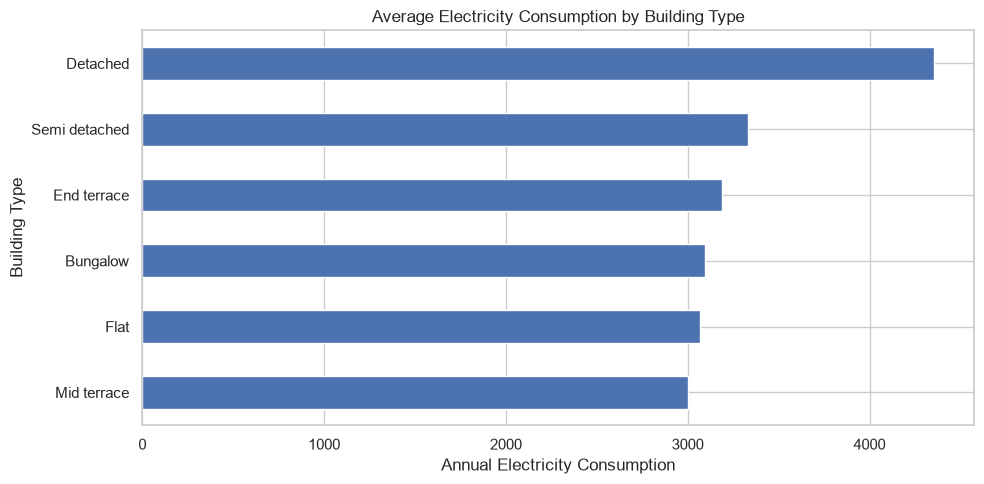

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

energy_by_type = (
    df_clean.groupby("PROP_TYPE")["Econs2024"]
    .mean()
    .sort_values()
)

energy_by_type.plot(kind="barh", figsize=(10, 5))

plt.title("Average Electricity Consumption by Building Type")
plt.xlabel("Annual Electricity Consumption")
plt.ylabel("Building Type")
plt.tight_layout()
save_fig("average_energy_by_building_type")
plt.show()

Figure saved to figures\epc_distribution.png


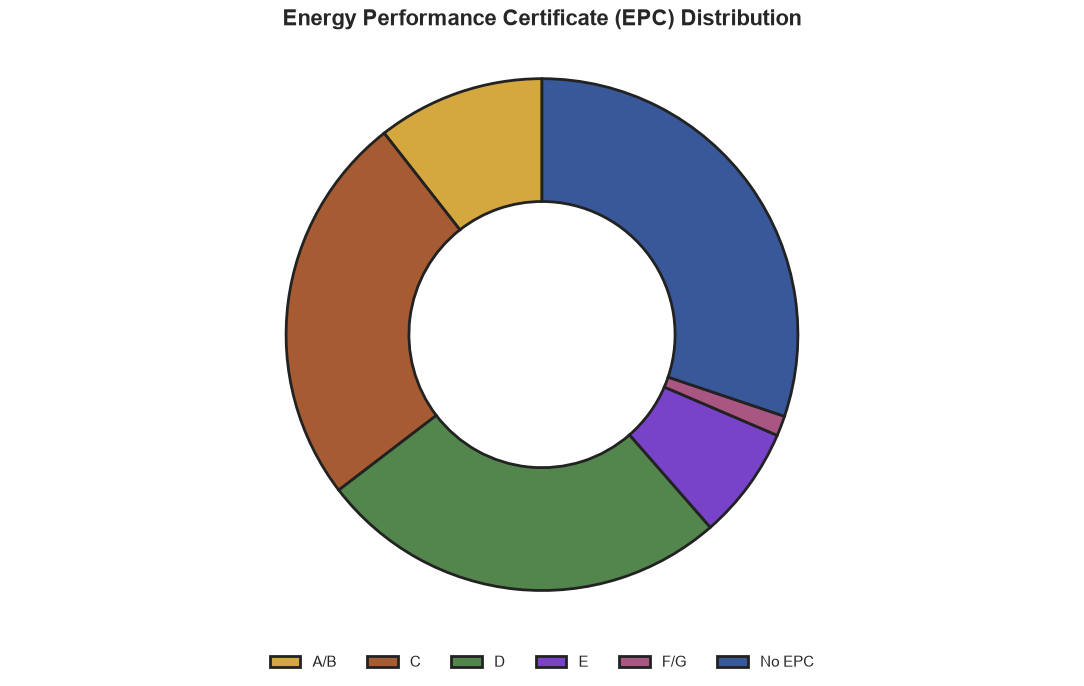

,EPC category,Properties,Percentage
0,No recorded EPC,15086,30.17
1,D,13015,26.03
2,C,12408,24.82
3,A/B,5289,10.58
4,E,3565,7.13
5,F/G,635,1.27


In [20]:
# 1. Prepare EPC data
epc = df_clean["EPC"].copy()

# Convert EPC codes into categories
epc = epc.fillna("No EPC").astype(str).str.strip().str.upper()

epc = epc.replace({
    "NAN": "No EPC",
    "NONE": "No EPC",
    "": "No EPC"
})

# Combine A and B, and F and G
epc = epc.replace({
    "A": "A/B",
    "B": "A/B",
    "F": "F/G",
    "G": "F/G",
    "NO EPC": "No EPC"
})

# 2. Count properties
categories = ["A/B", "C", "D", "E", "F/G", "No EPC"]

epc_counts = epc.value_counts().reindex(
    categories, fill_value=0
)

# 3. Define chart colors
colors = [
    "#D4A83F",  # A/B - Gold
    "#A65B32",  # C - Brown
    "#53864D",  # D - Green
    "#7843C9",  # E - Purple
    "#A95782",  # F/G - Pink
    "#38589A"   # No EPC - Blue
]

# 4. Create donut chart
fig, ax = plt.subplots(figsize=(11, 7))

wedges, texts = ax.pie(
    epc_counts.values,
    colors=colors,
    startangle=90,
    wedgeprops={
        "width": 0.48,
        "edgecolor": "#222222",
        "linewidth": 2
    }
)

ax.set_title(
    "Energy Performance Certificate (EPC) Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.legend(
    wedges,
    categories,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=6,
    frameon=False
)

ax.axis("equal")

plt.tight_layout()
save_fig("epc_distribution")
plt.show()

# 5. Create EPC summary table
epc_table = pd.DataFrame({
    "EPC category": [
        "No recorded EPC", "D", "C", "A/B", "E", "F/G"
    ],
    "Properties": [
        epc_counts["No EPC"],
        epc_counts["D"],
        epc_counts["C"],
        epc_counts["A/B"],
        epc_counts["E"],
        epc_counts["F/G"]
    ]
})

epc_table["Percentage"] = (
    epc_table["Properties"] / len(df_clean) * 100
).round(2)

display(epc_table)

Figure saved to figures\average_annual_gas_consumption.png


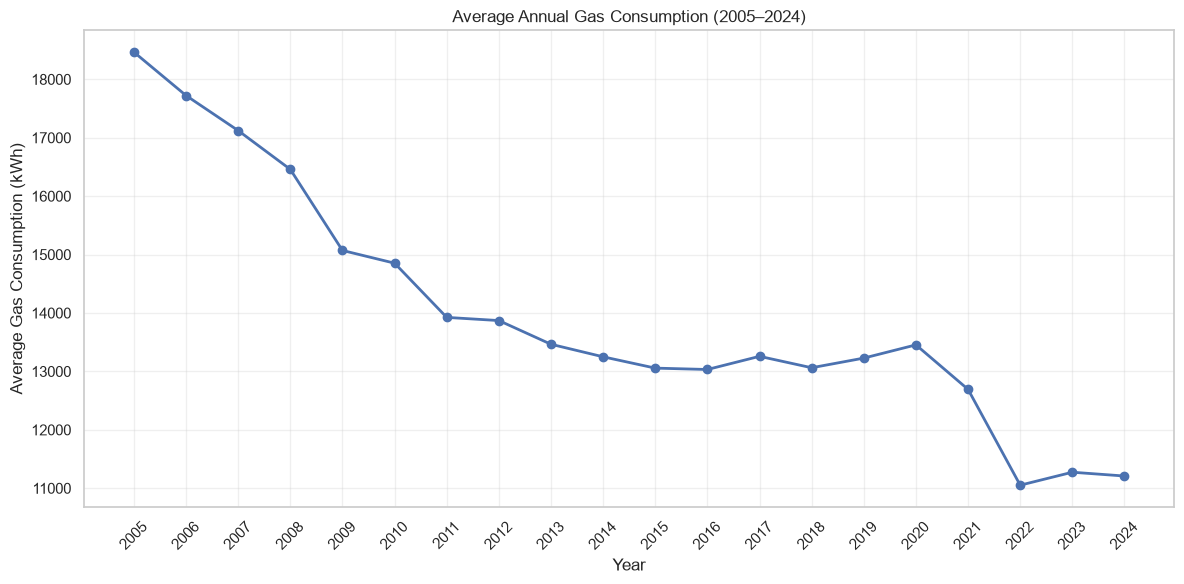

In [21]:
# Years from 2005 to 2024
years = list(range(2005, 2025))

# Column names
gas_columns = [f"Gcons{year}" for year in years]

# Calculate average gas consumption
gas_average = (
    df_clean[gas_columns]
    .apply(pd.to_numeric, errors="coerce")
    .mean()
)

# Create line graph
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    gas_average.values,
    marker="o",
    linewidth=2
)

plt.title("Average Annual Gas Consumption (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Average Gas Consumption (kWh)")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("average_annual_gas_consumption")
plt.show()

Figure saved to figures\average_annual_electricity_consumption.png


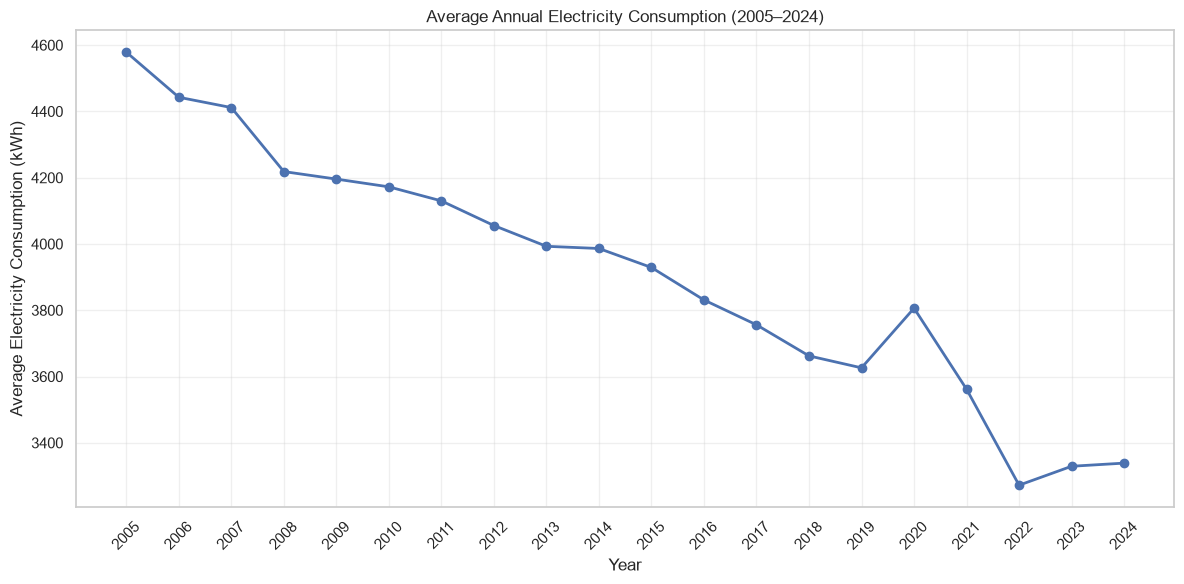

In [22]:
# Column names
electricity_columns = [f"Econs{year}" for year in years]

# Calculate average electricity consumption
electricity_average = (
    df_clean[electricity_columns]
    .apply(pd.to_numeric, errors="coerce")
    .mean()
)

# Create line graph
plt.figure(figsize=(12, 6))

plt.plot(
    years,
    electricity_average.values,
    marker="o",
    linewidth=2
)

plt.title("Average Annual Electricity Consumption (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Average Electricity Consumption (kWh)")
plt.xticks(years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("average_annual_electricity_consumption")
plt.show()

Figure saved to figures\gas_vs_electricity_consumption_trends.png


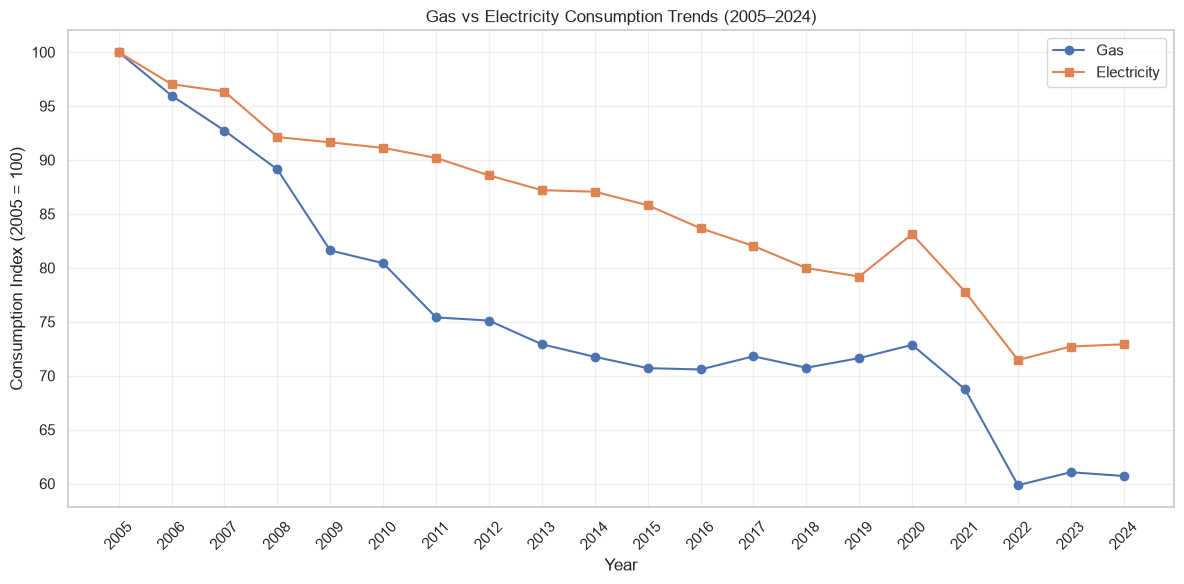

In [23]:
gas_index = gas_average.values / gas_average.iloc[0] * 100
electricity_index = (
    electricity_average.values / electricity_average.iloc[0] * 100
)

plt.figure(figsize=(12, 6))

plt.plot(years, gas_index, marker="o", label="Gas")
plt.plot(years, electricity_index, marker="s", label="Electricity")

plt.title("Gas vs Electricity Consumption Trends (2005–2024)")
plt.xlabel("Year")
plt.ylabel("Consumption Index (2005 = 100)")
plt.xticks(years, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("gas_vs_electricity_consumption_trends")
plt.show()

In [24]:
energy_summary = pd.DataFrame({
    "Year": years,
    "Average Gas Consumption": gas_average.values,
    "Average Electricity Consumption": electricity_average.values
})

display(energy_summary.round(2))

,Year,Average Gas Consumption,Average Electricity Consumption
0,2005,"18,465.19","4,578.83"
1,2006,"17,722.09","4,442.63"
2,2007,"17,121.84","4,411.57"
3,2008,"16,457.95","4,218.39"
4,2009,"15,070.04","4,195.71"
5,2010,"14,852.24","4,172.32"
6,2011,"13,924.31","4,129.92"
7,2012,"13,869.94","4,055.57"
8,2013,"13,464.25","3,992.93"
9,2014,"13,249.55","3,986.28"
